# Figures S5-S12 - Sensitivity of the FS-peptide analysis to the histogram bin width

Lotthammer, J. M. & Holehouse, A. S. *Disentangling folding from energetic traps in simulations of disordered proteins.* **J. Chem. Inf. Model.** (2025). doi:[10.1021/acs.jcim.4c02005](https://doi.org/10.1021/acs.jcim.4c02005)

**What the figures show.** PENGUIN discretises the (φ, ψ) plane into bins before comparing distributions, so the absolute Hellinger distance depends on the bin width. Figures S5-S10 are the full four-panel PENGUIN summary for the FS-peptide at bin widths of 5, 15, 30, 45, 60 and 120°; Figures S11 and S12 overlay the replicate-mean EV-comparison and all-to-all curves across those widths.

**What to look for.** Finer bins inflate every distance (there are more bins for the two finite samples to disagree in), and very coarse bins compress everything towards zero, but the *shape* of the per-residue profile - which residues are restricted, and whether replicates agree - is stable. The manuscript uses 15°, and the paper argues that conclusions should be drawn from relative, not absolute, values. Compare with notebook 10, where a far more extensively sampled system is much less sensitive to bin width.

**Data.** The Figure 4 system (20 FH + 20 EV replicates). The trajectories are re-loaded for every width, so this notebook takes a few minutes.

## Setup

All notebooks in this directory share `penguin_helpers.py`, a thin layer over SOURSOP's public `soursop.sssampling.SamplingQuality` API that handles data discovery, the manuscript's matplotlib style, and the four-panel PENGUIN figure. The trajectories (~6 GB) live in `data/`, one folder per system with `full/` and `ev/` replicates (see `data/README.md`); they are too large for the SOURSOP repository, so set `PENGUIN_DATA_DIR` if you keep them elsewhere.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from penguin_helpers import (
    set_manuscript_style, get_data_dir, figure_path, load_system,
    penguin_figure, print_sequence,
)

set_manuscript_style()
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

DATA_DIR = get_data_dir()
print("Reading simulation data from", DATA_DIR)
from penguin_helpers import mean_bin_width_curves, plot_bin_width_comparison

Reading simulation data from /Users/alex/Dropbox/WASHU/Holehouse/tools/soursop/soursop/demo_examples/penguin/data


## Four-panel summaries at each bin width (Figures S5-S10)

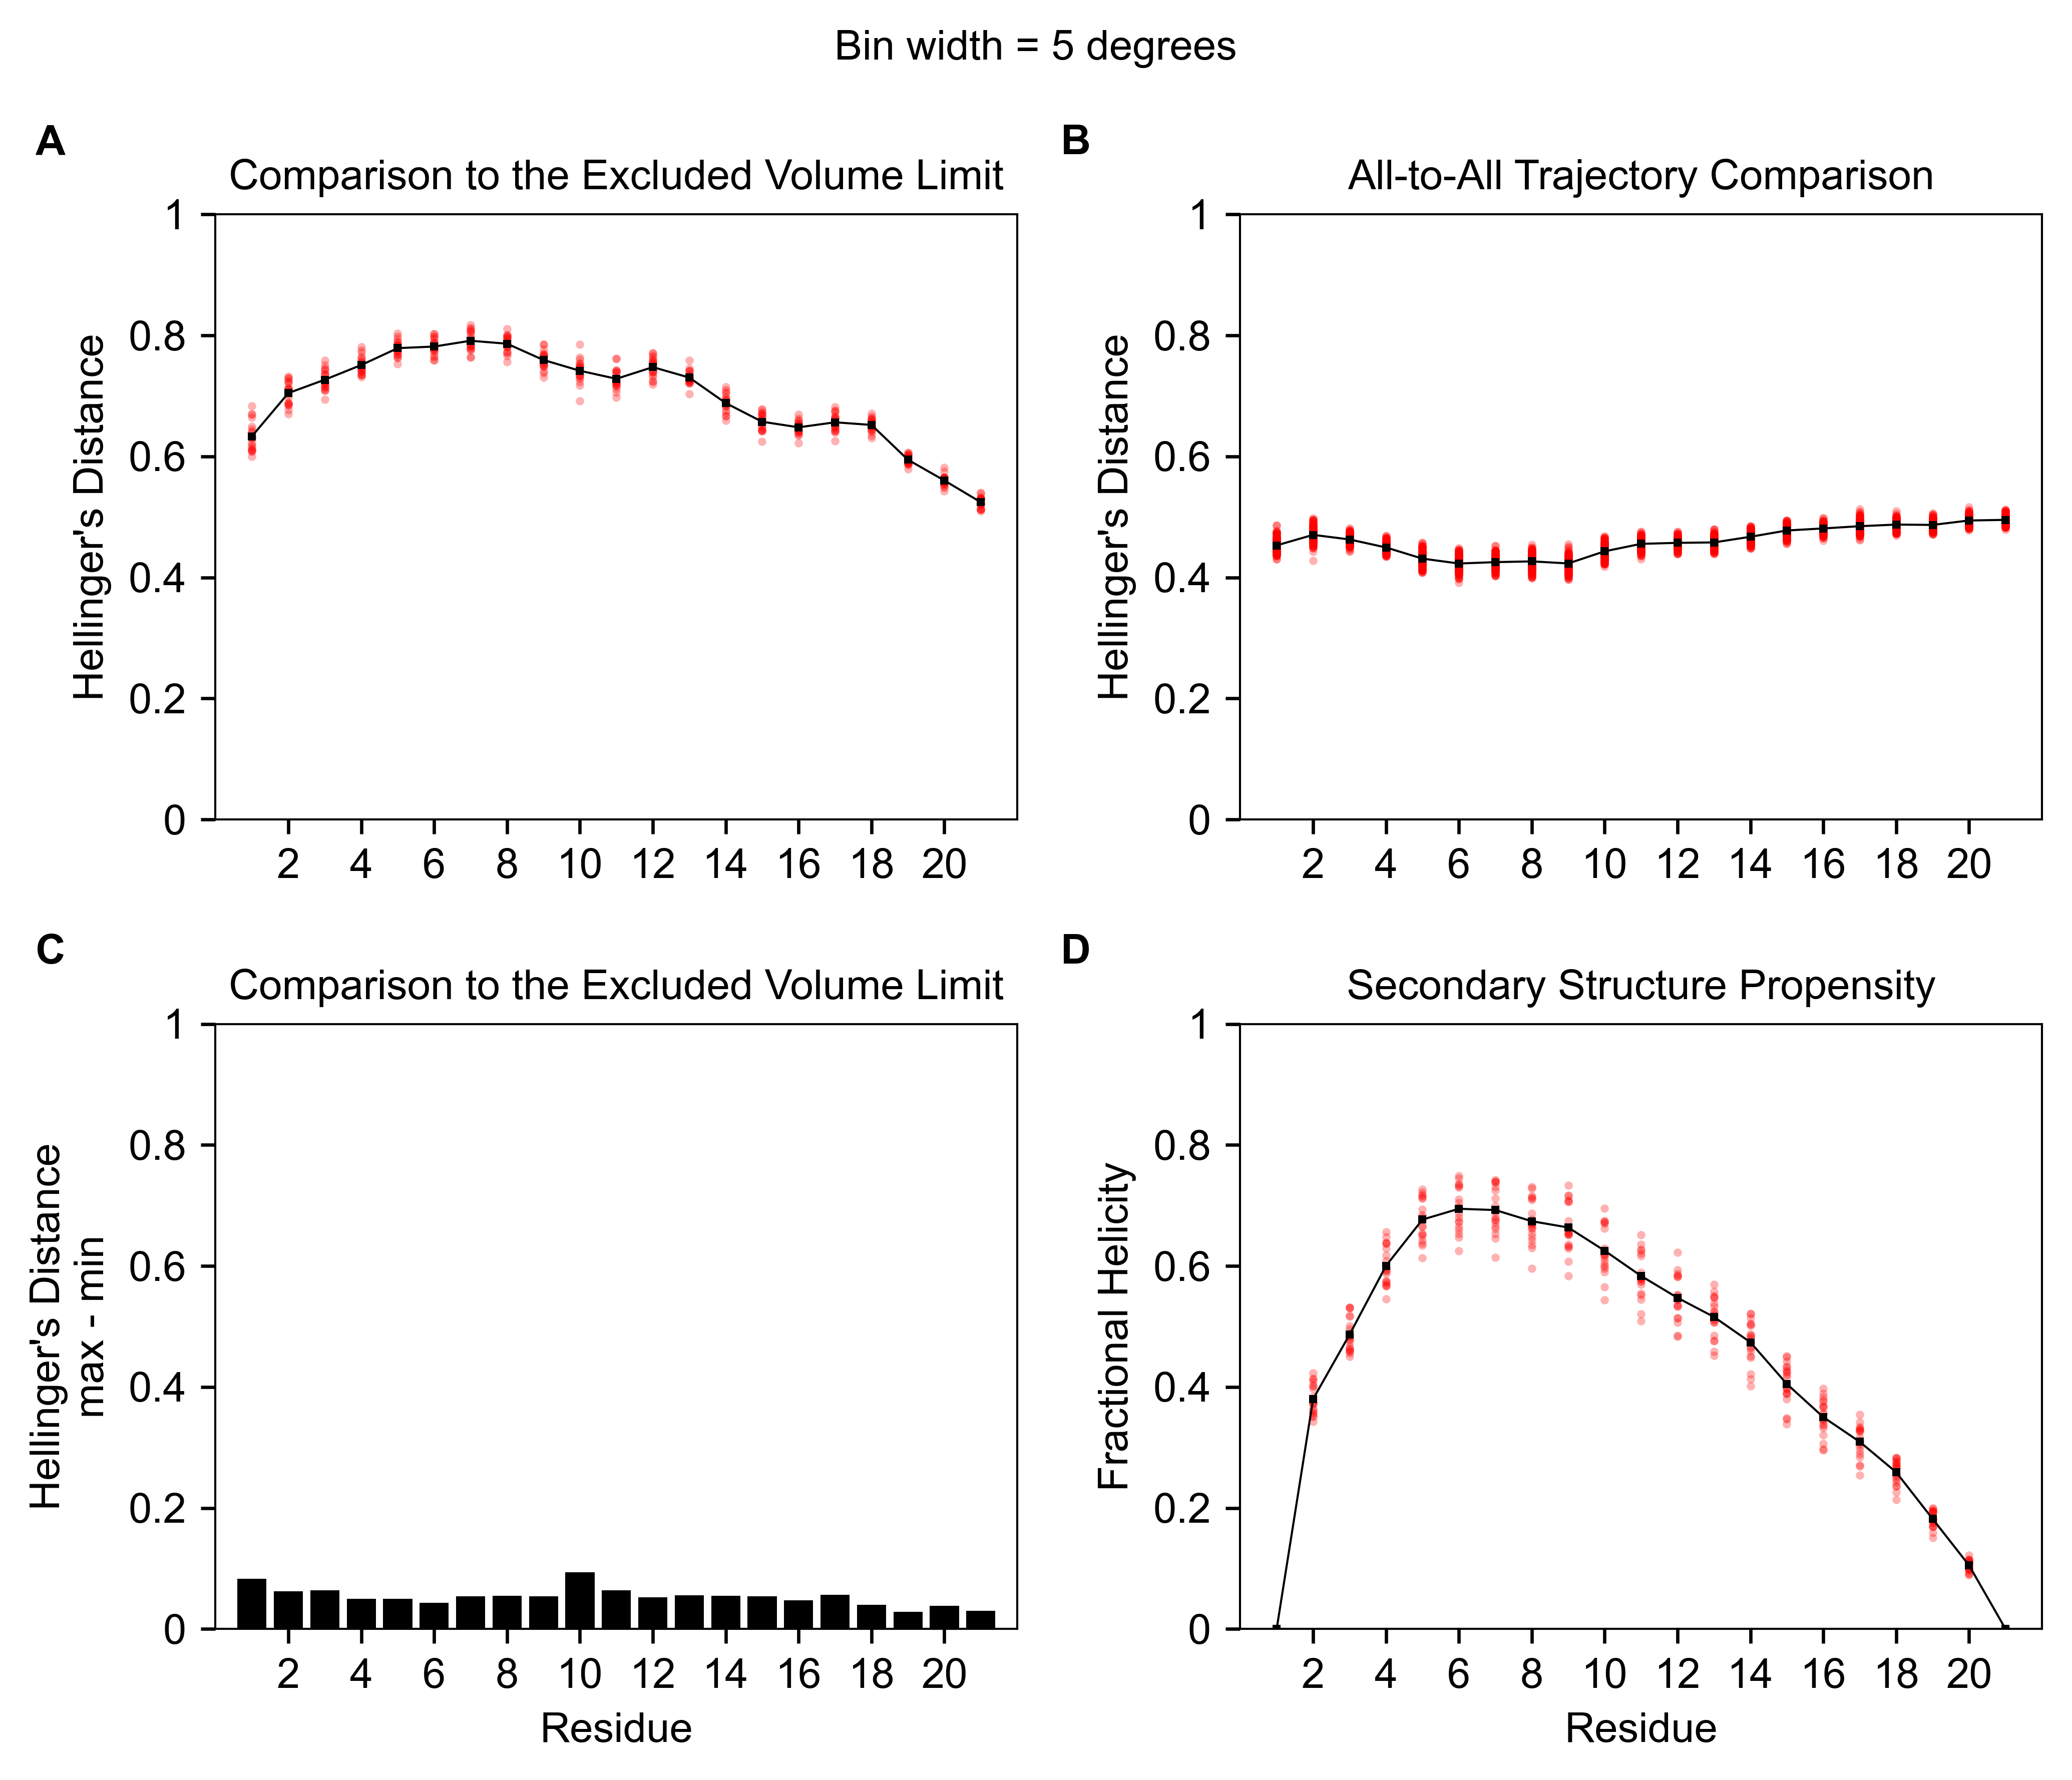

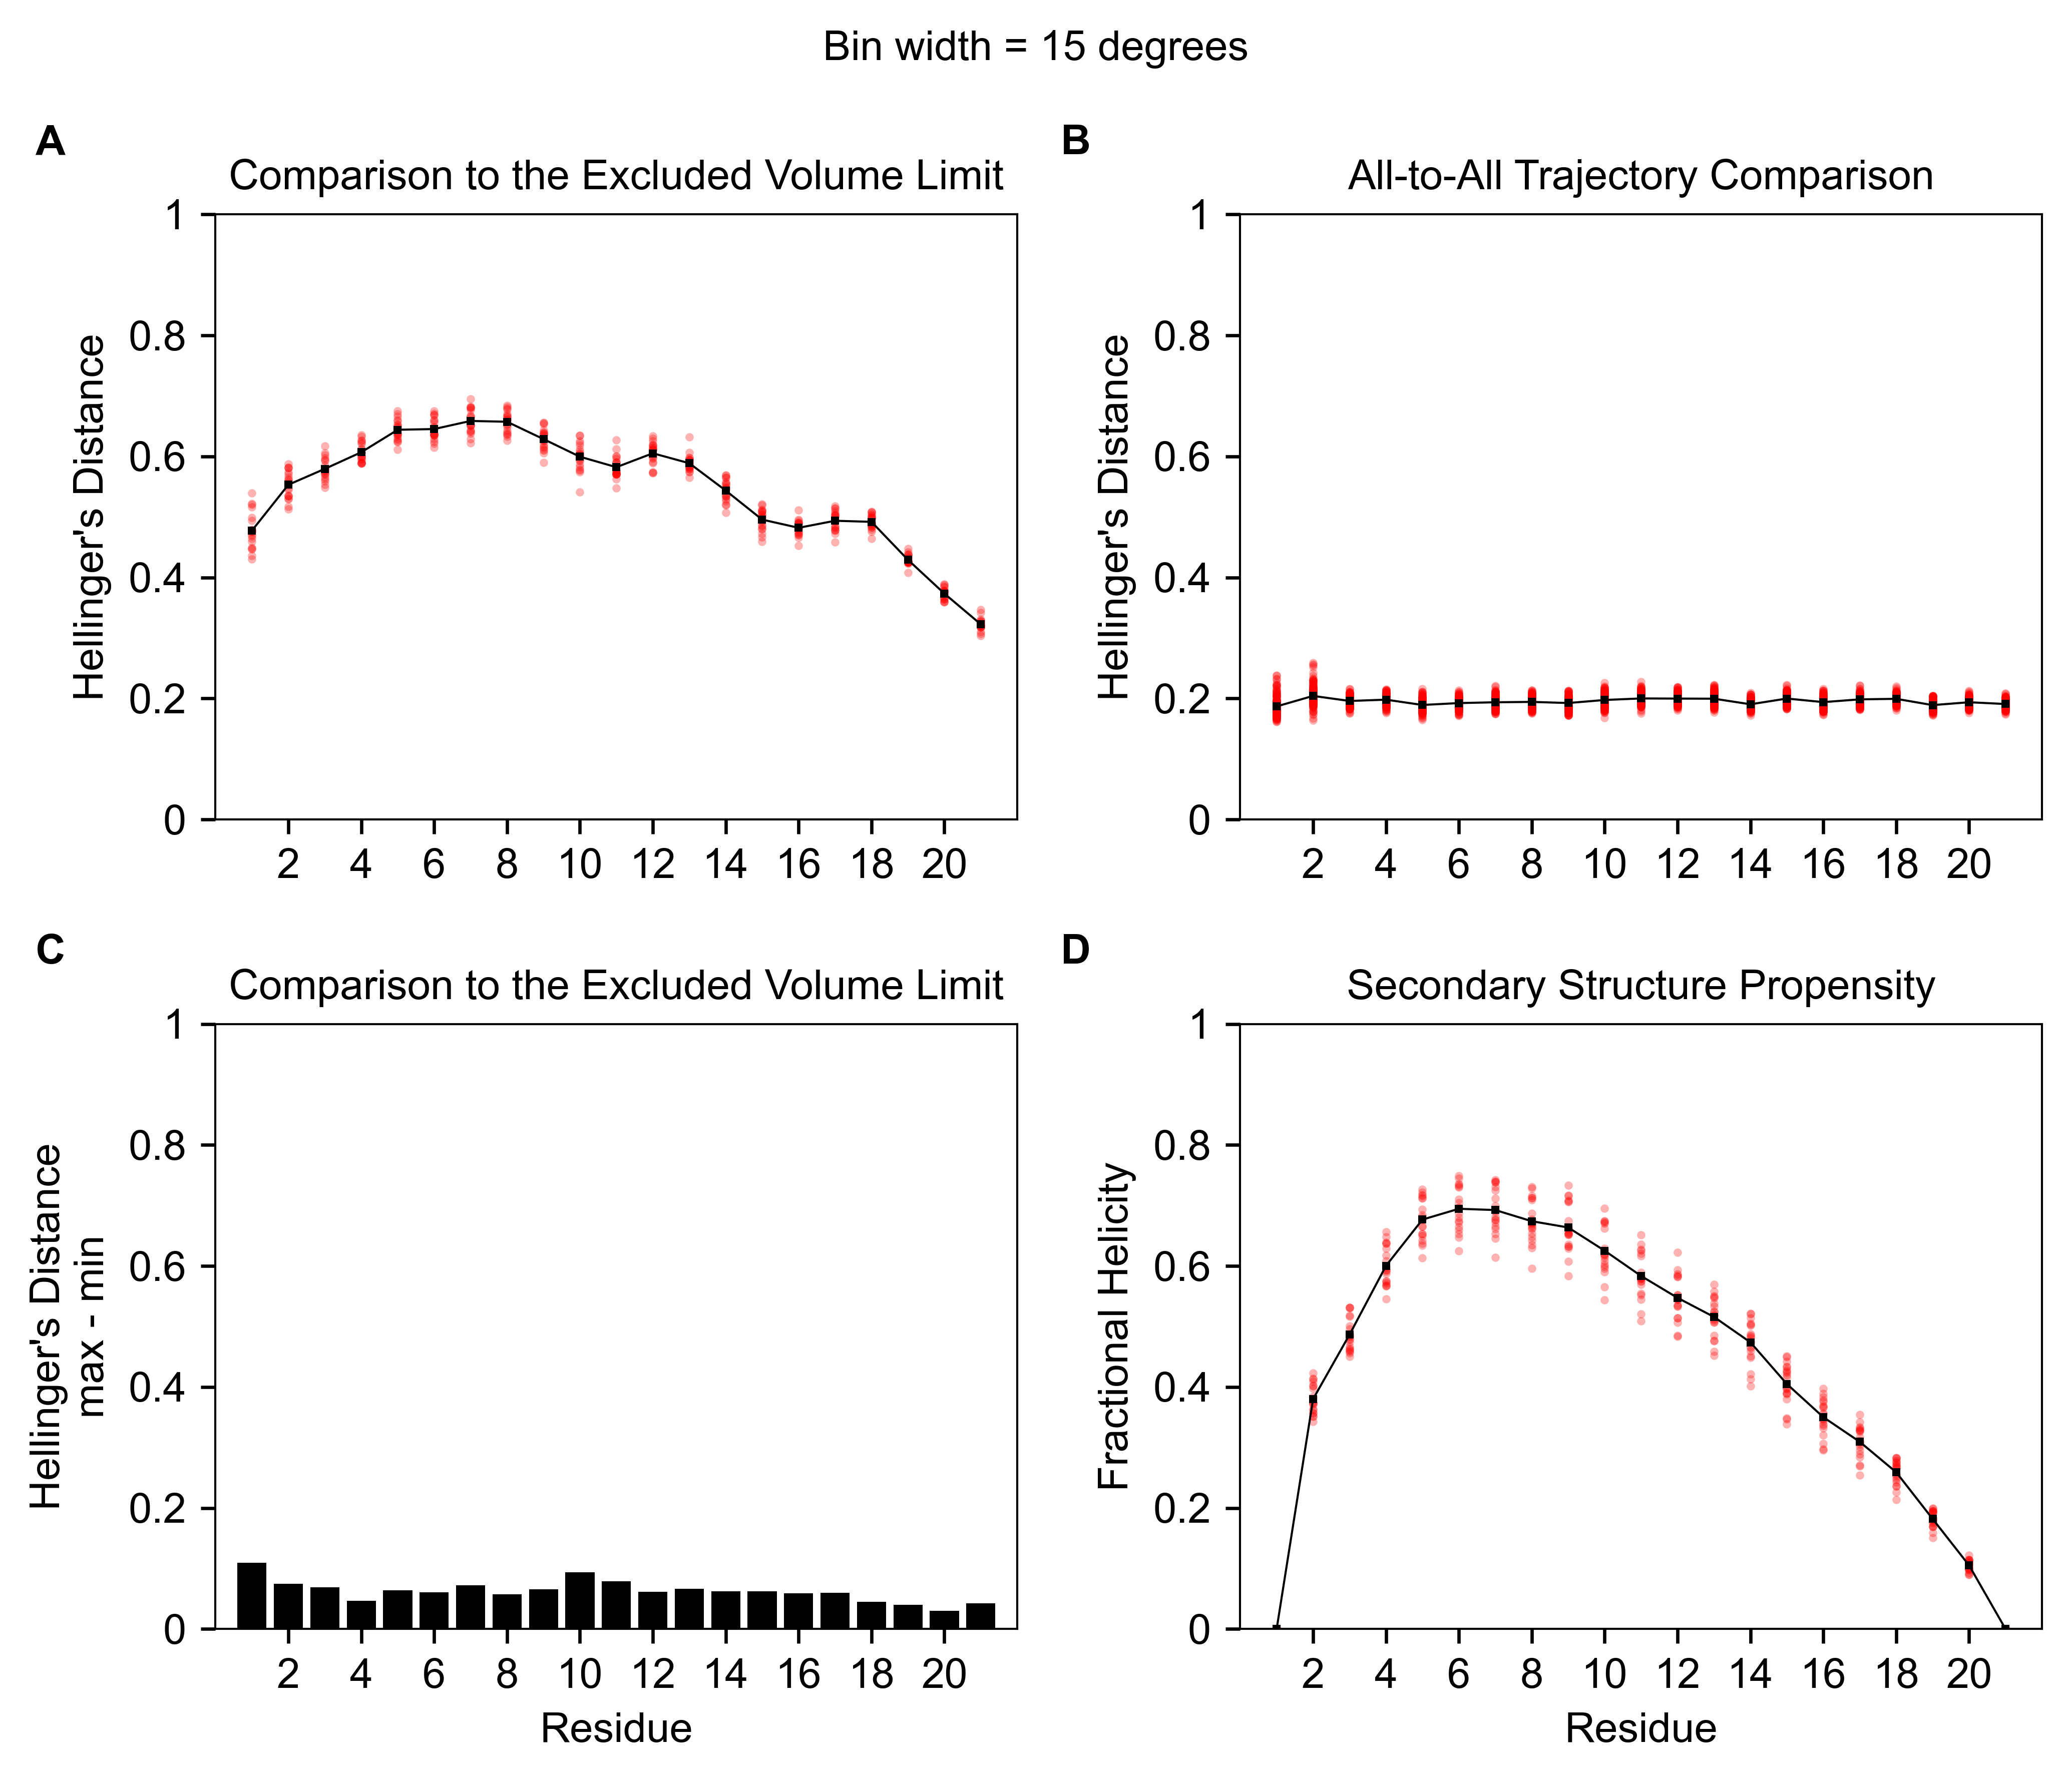

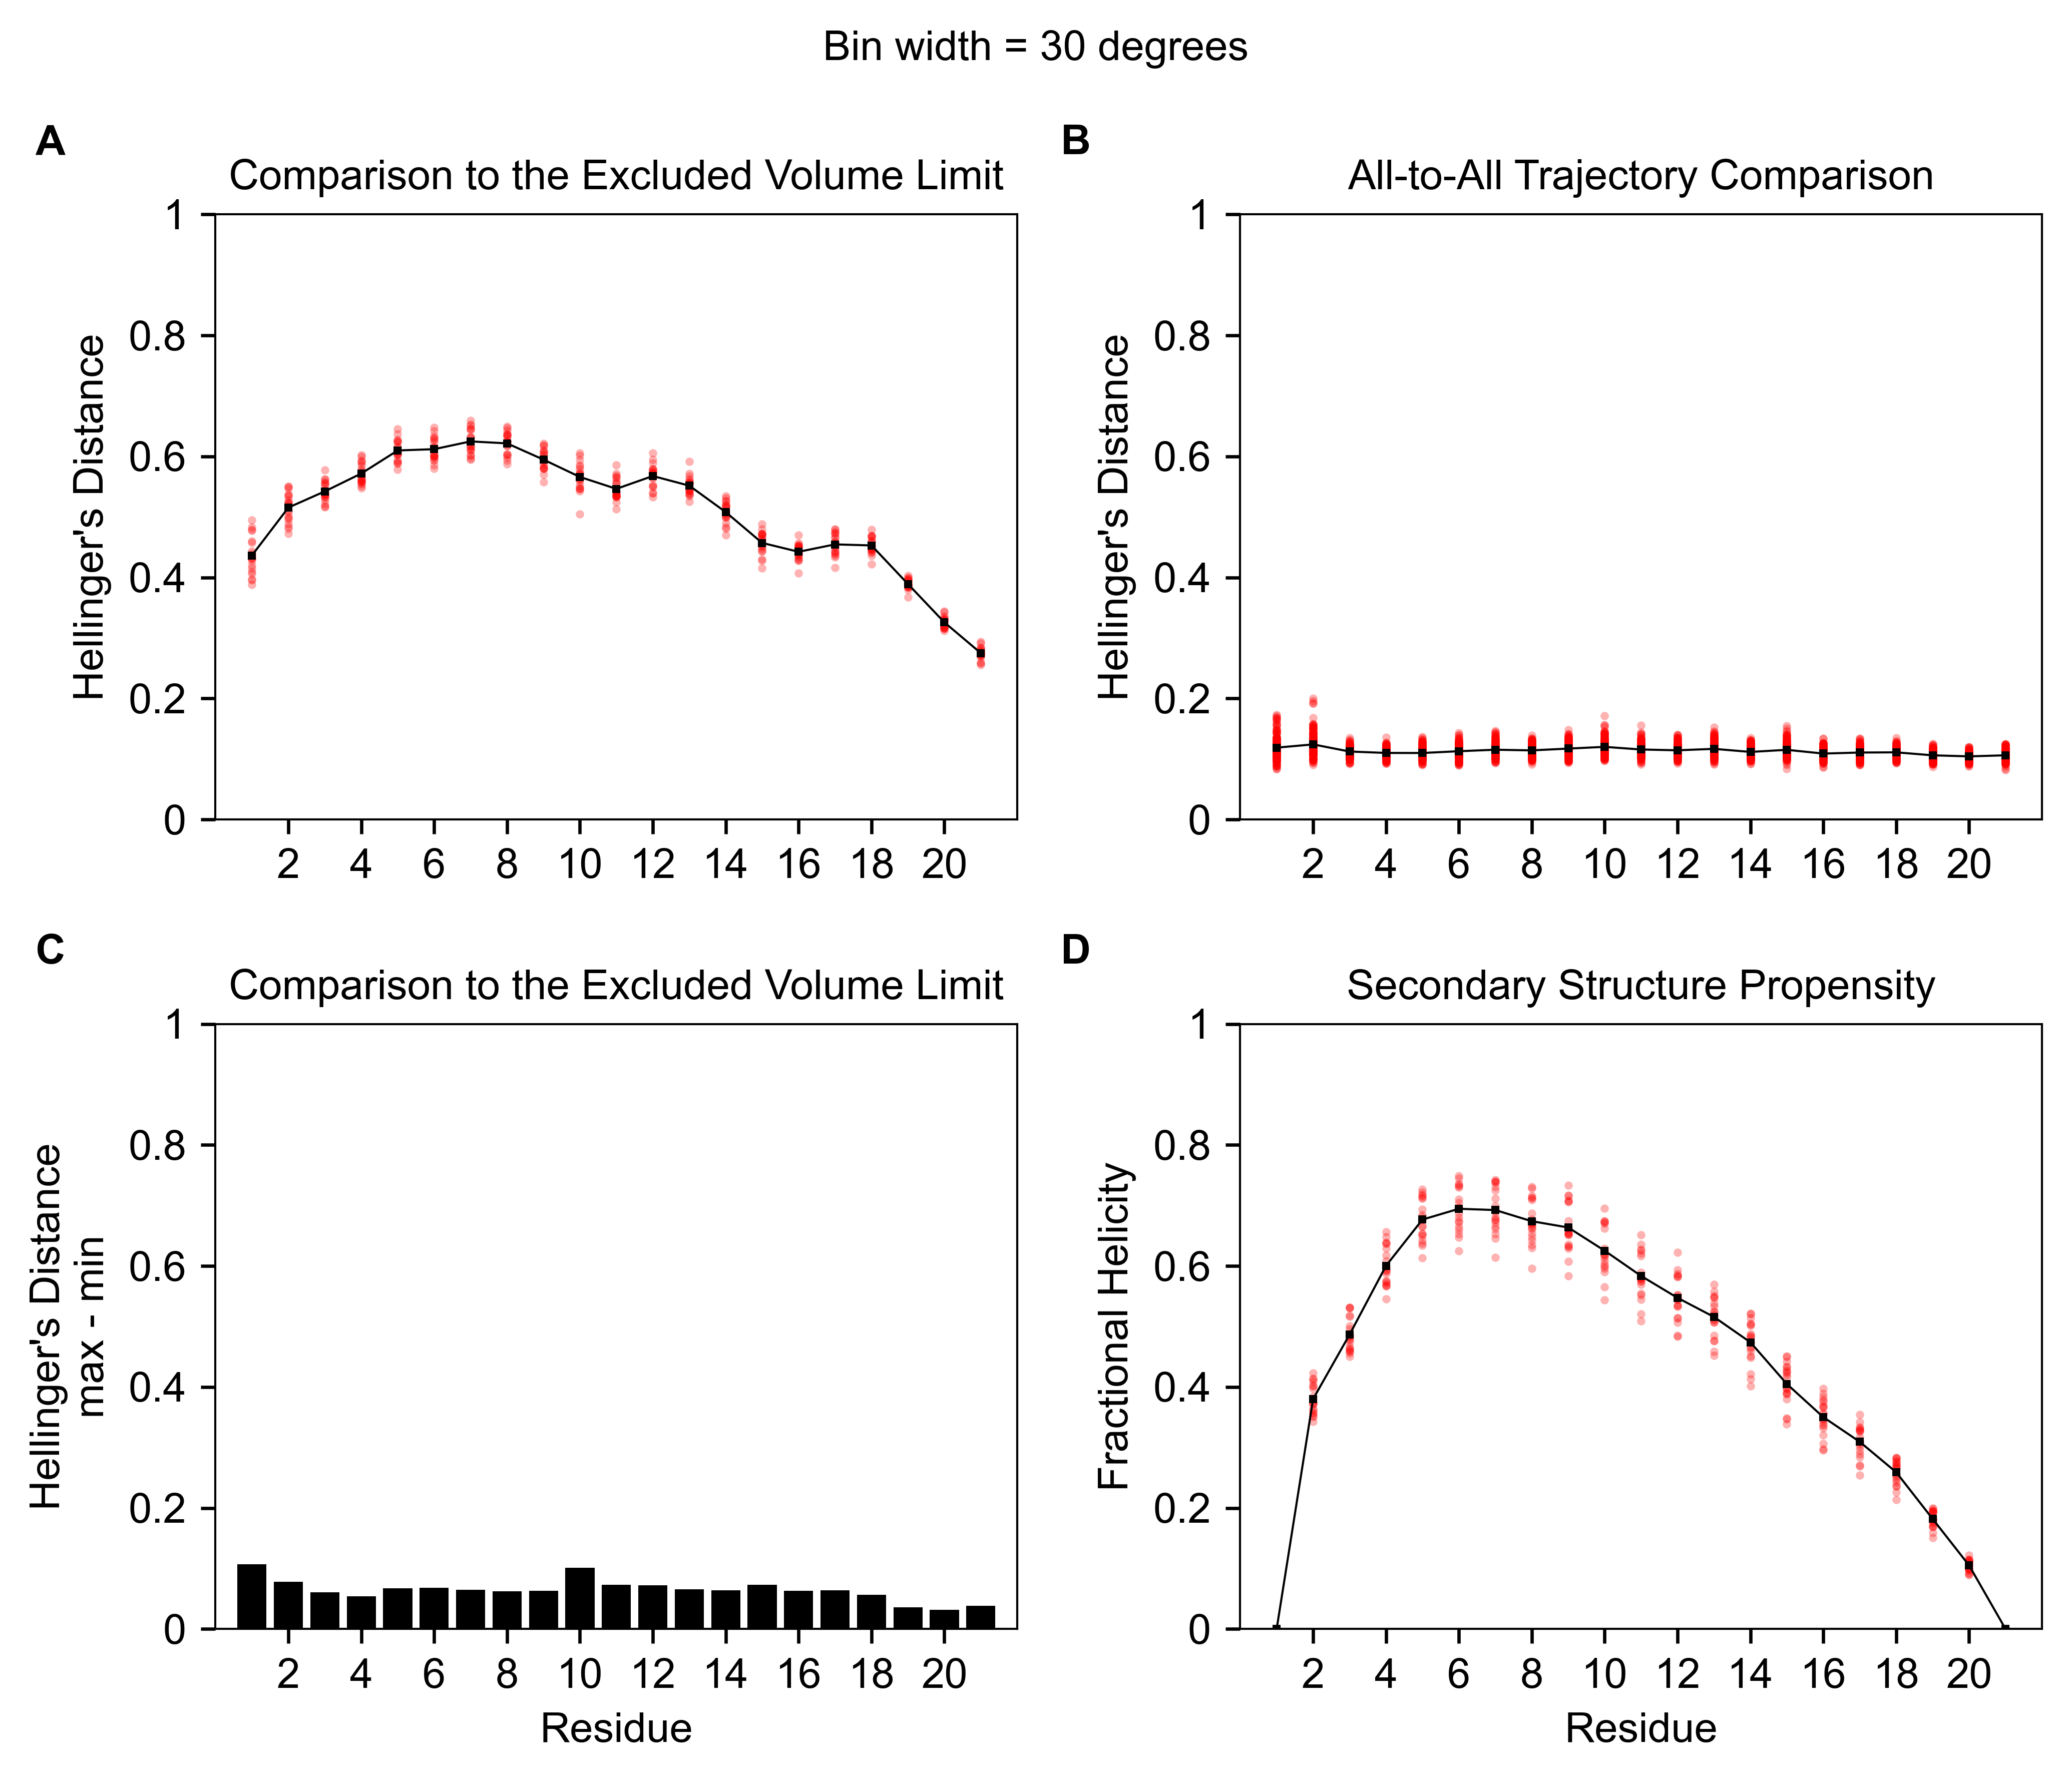

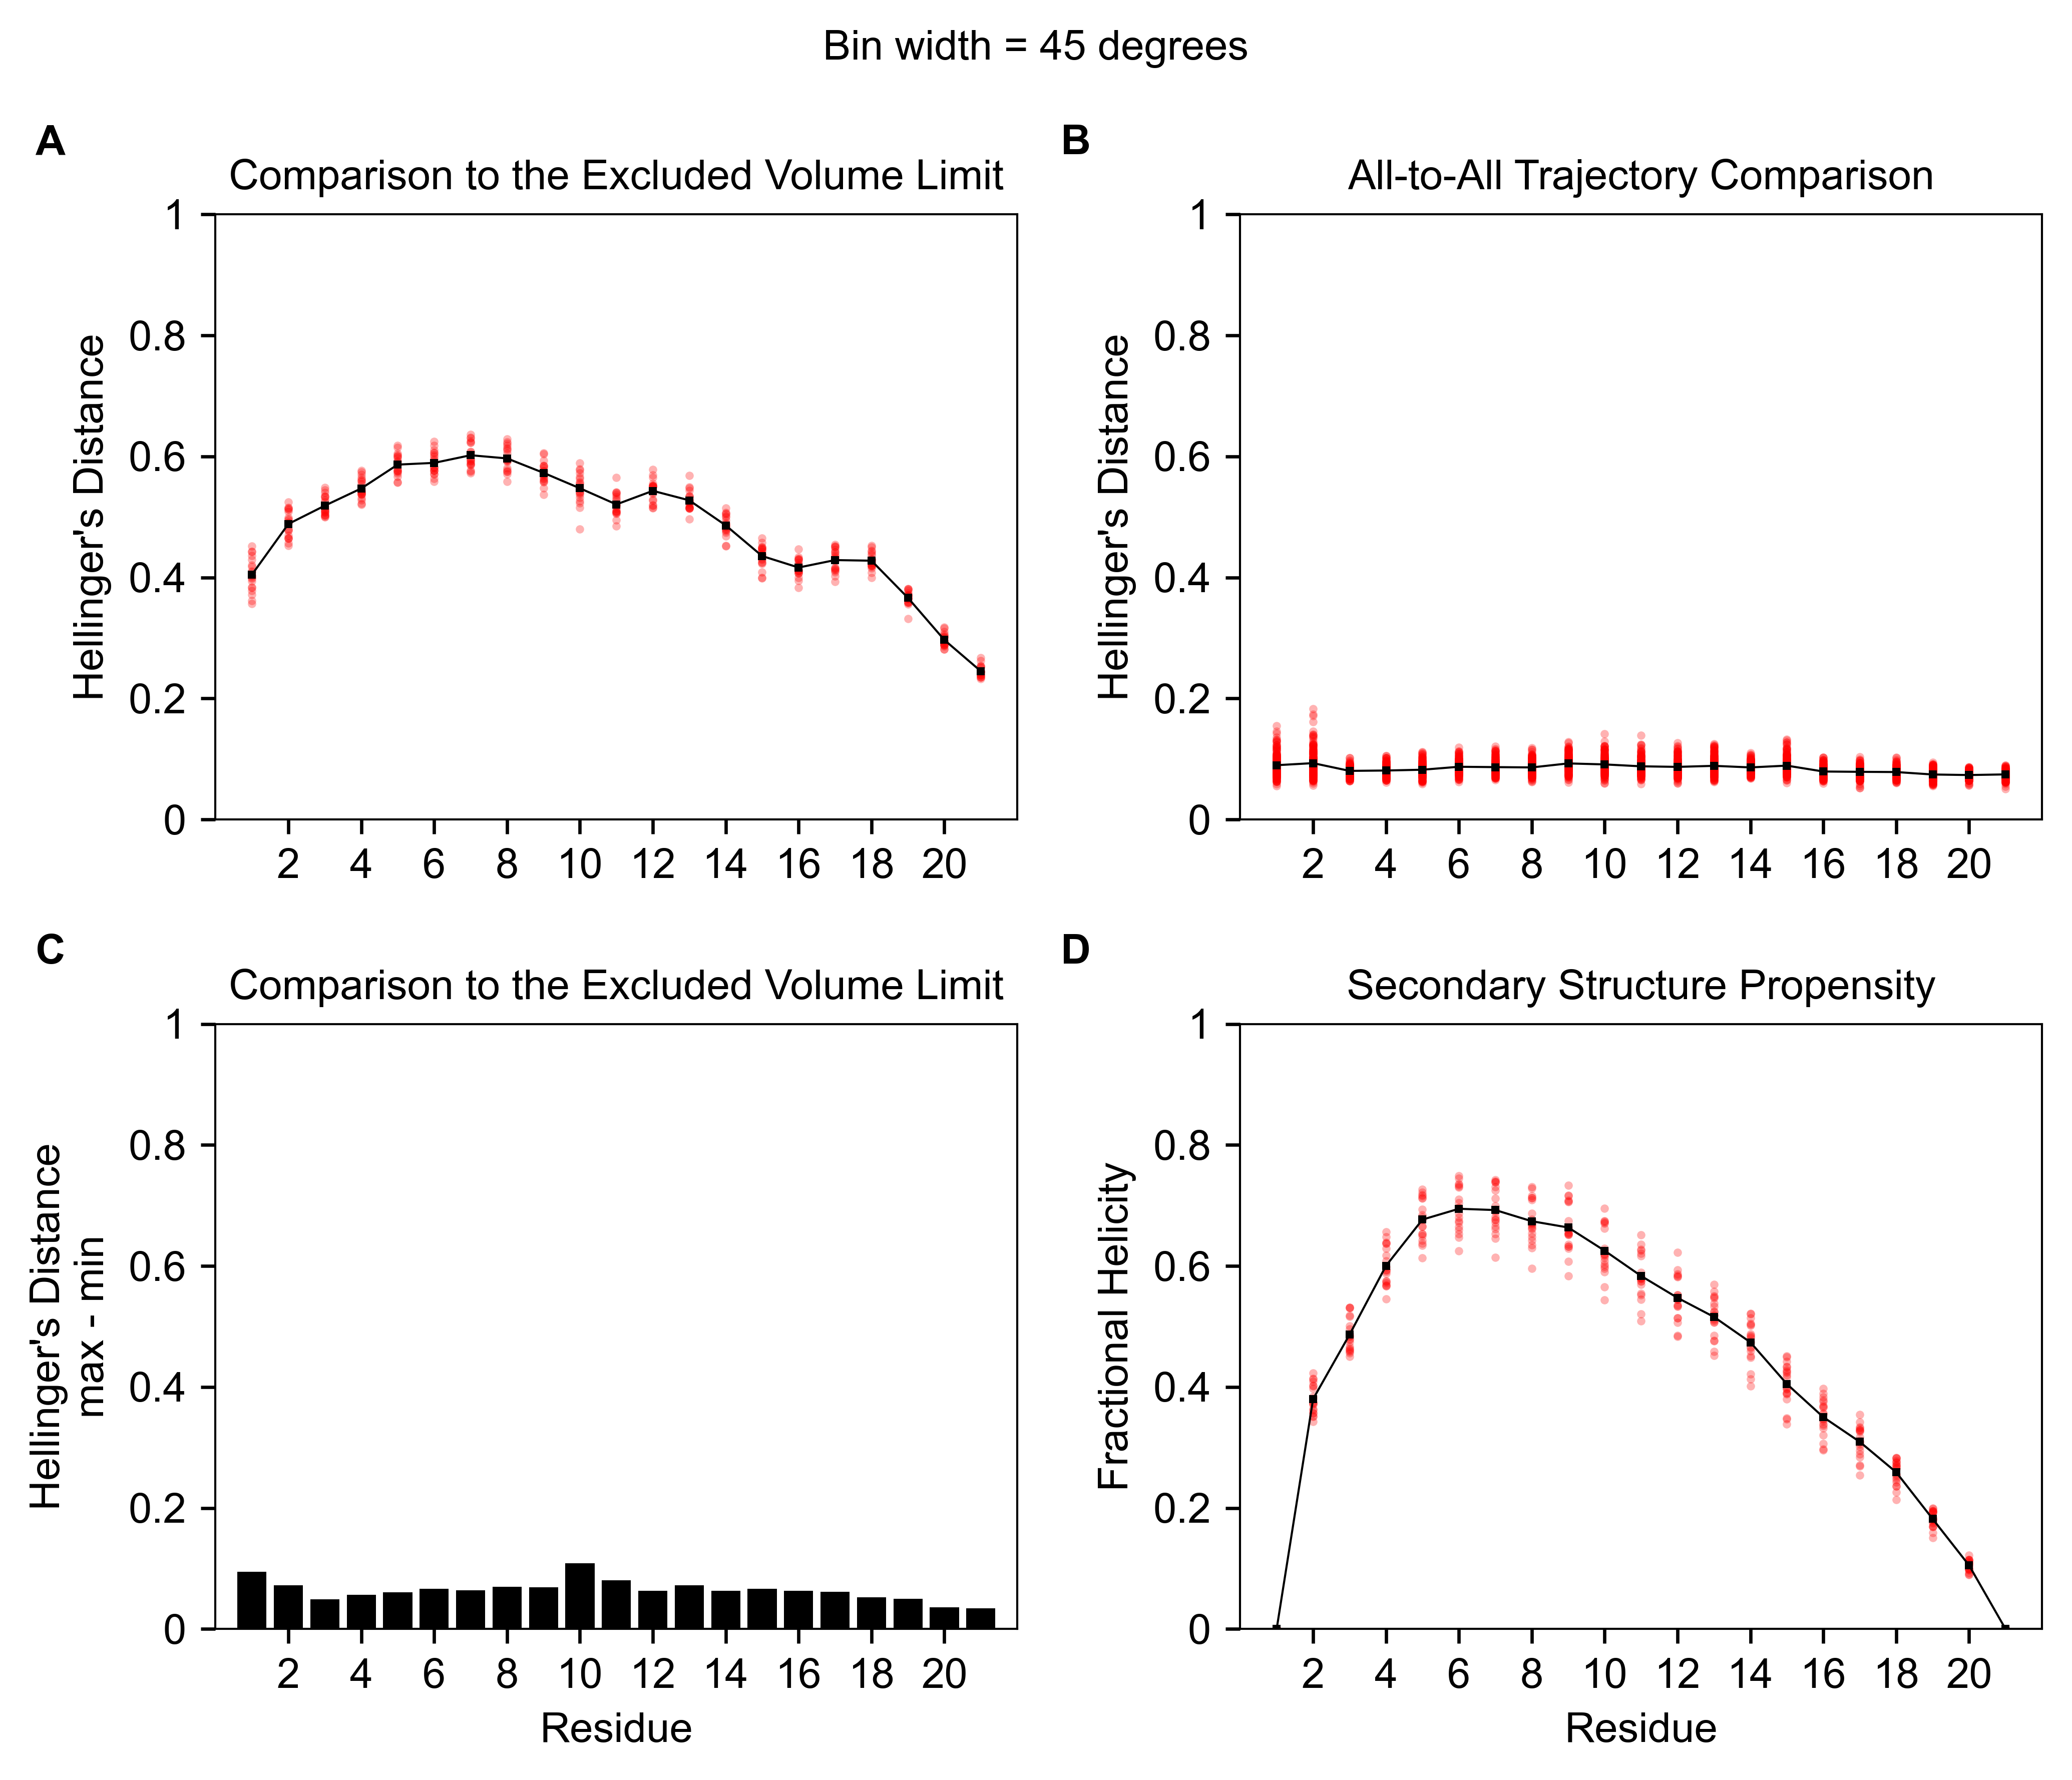

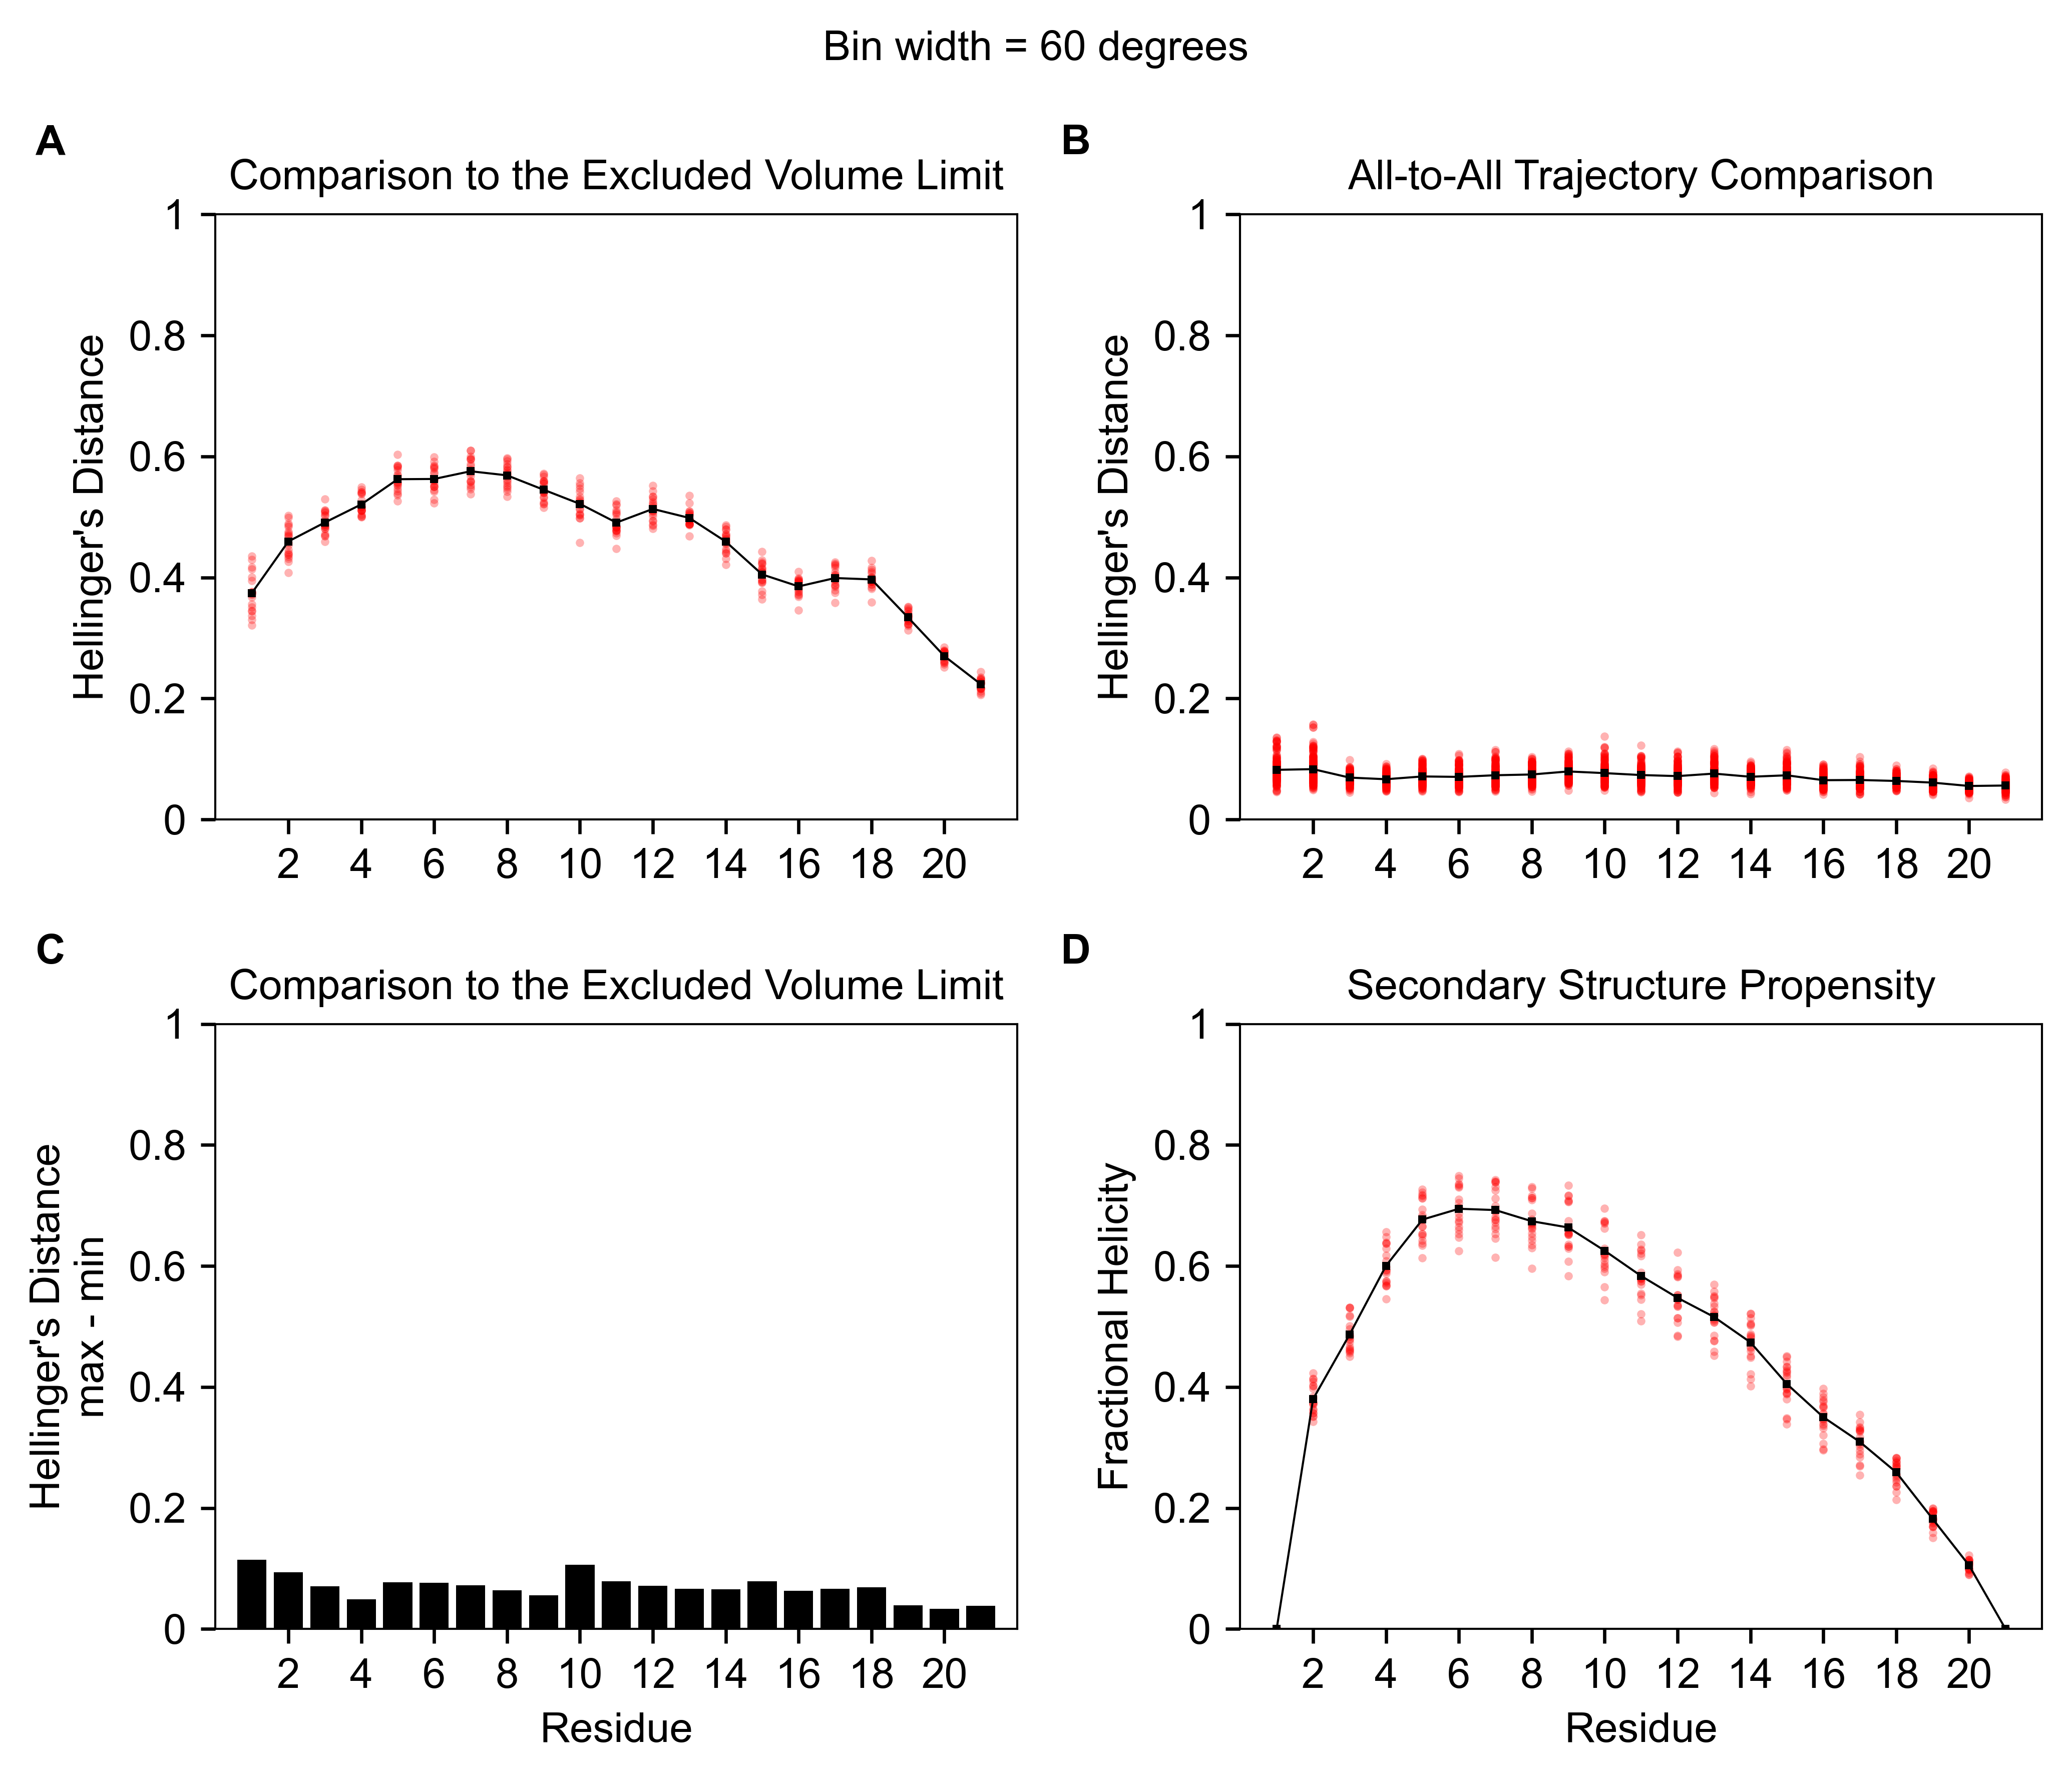

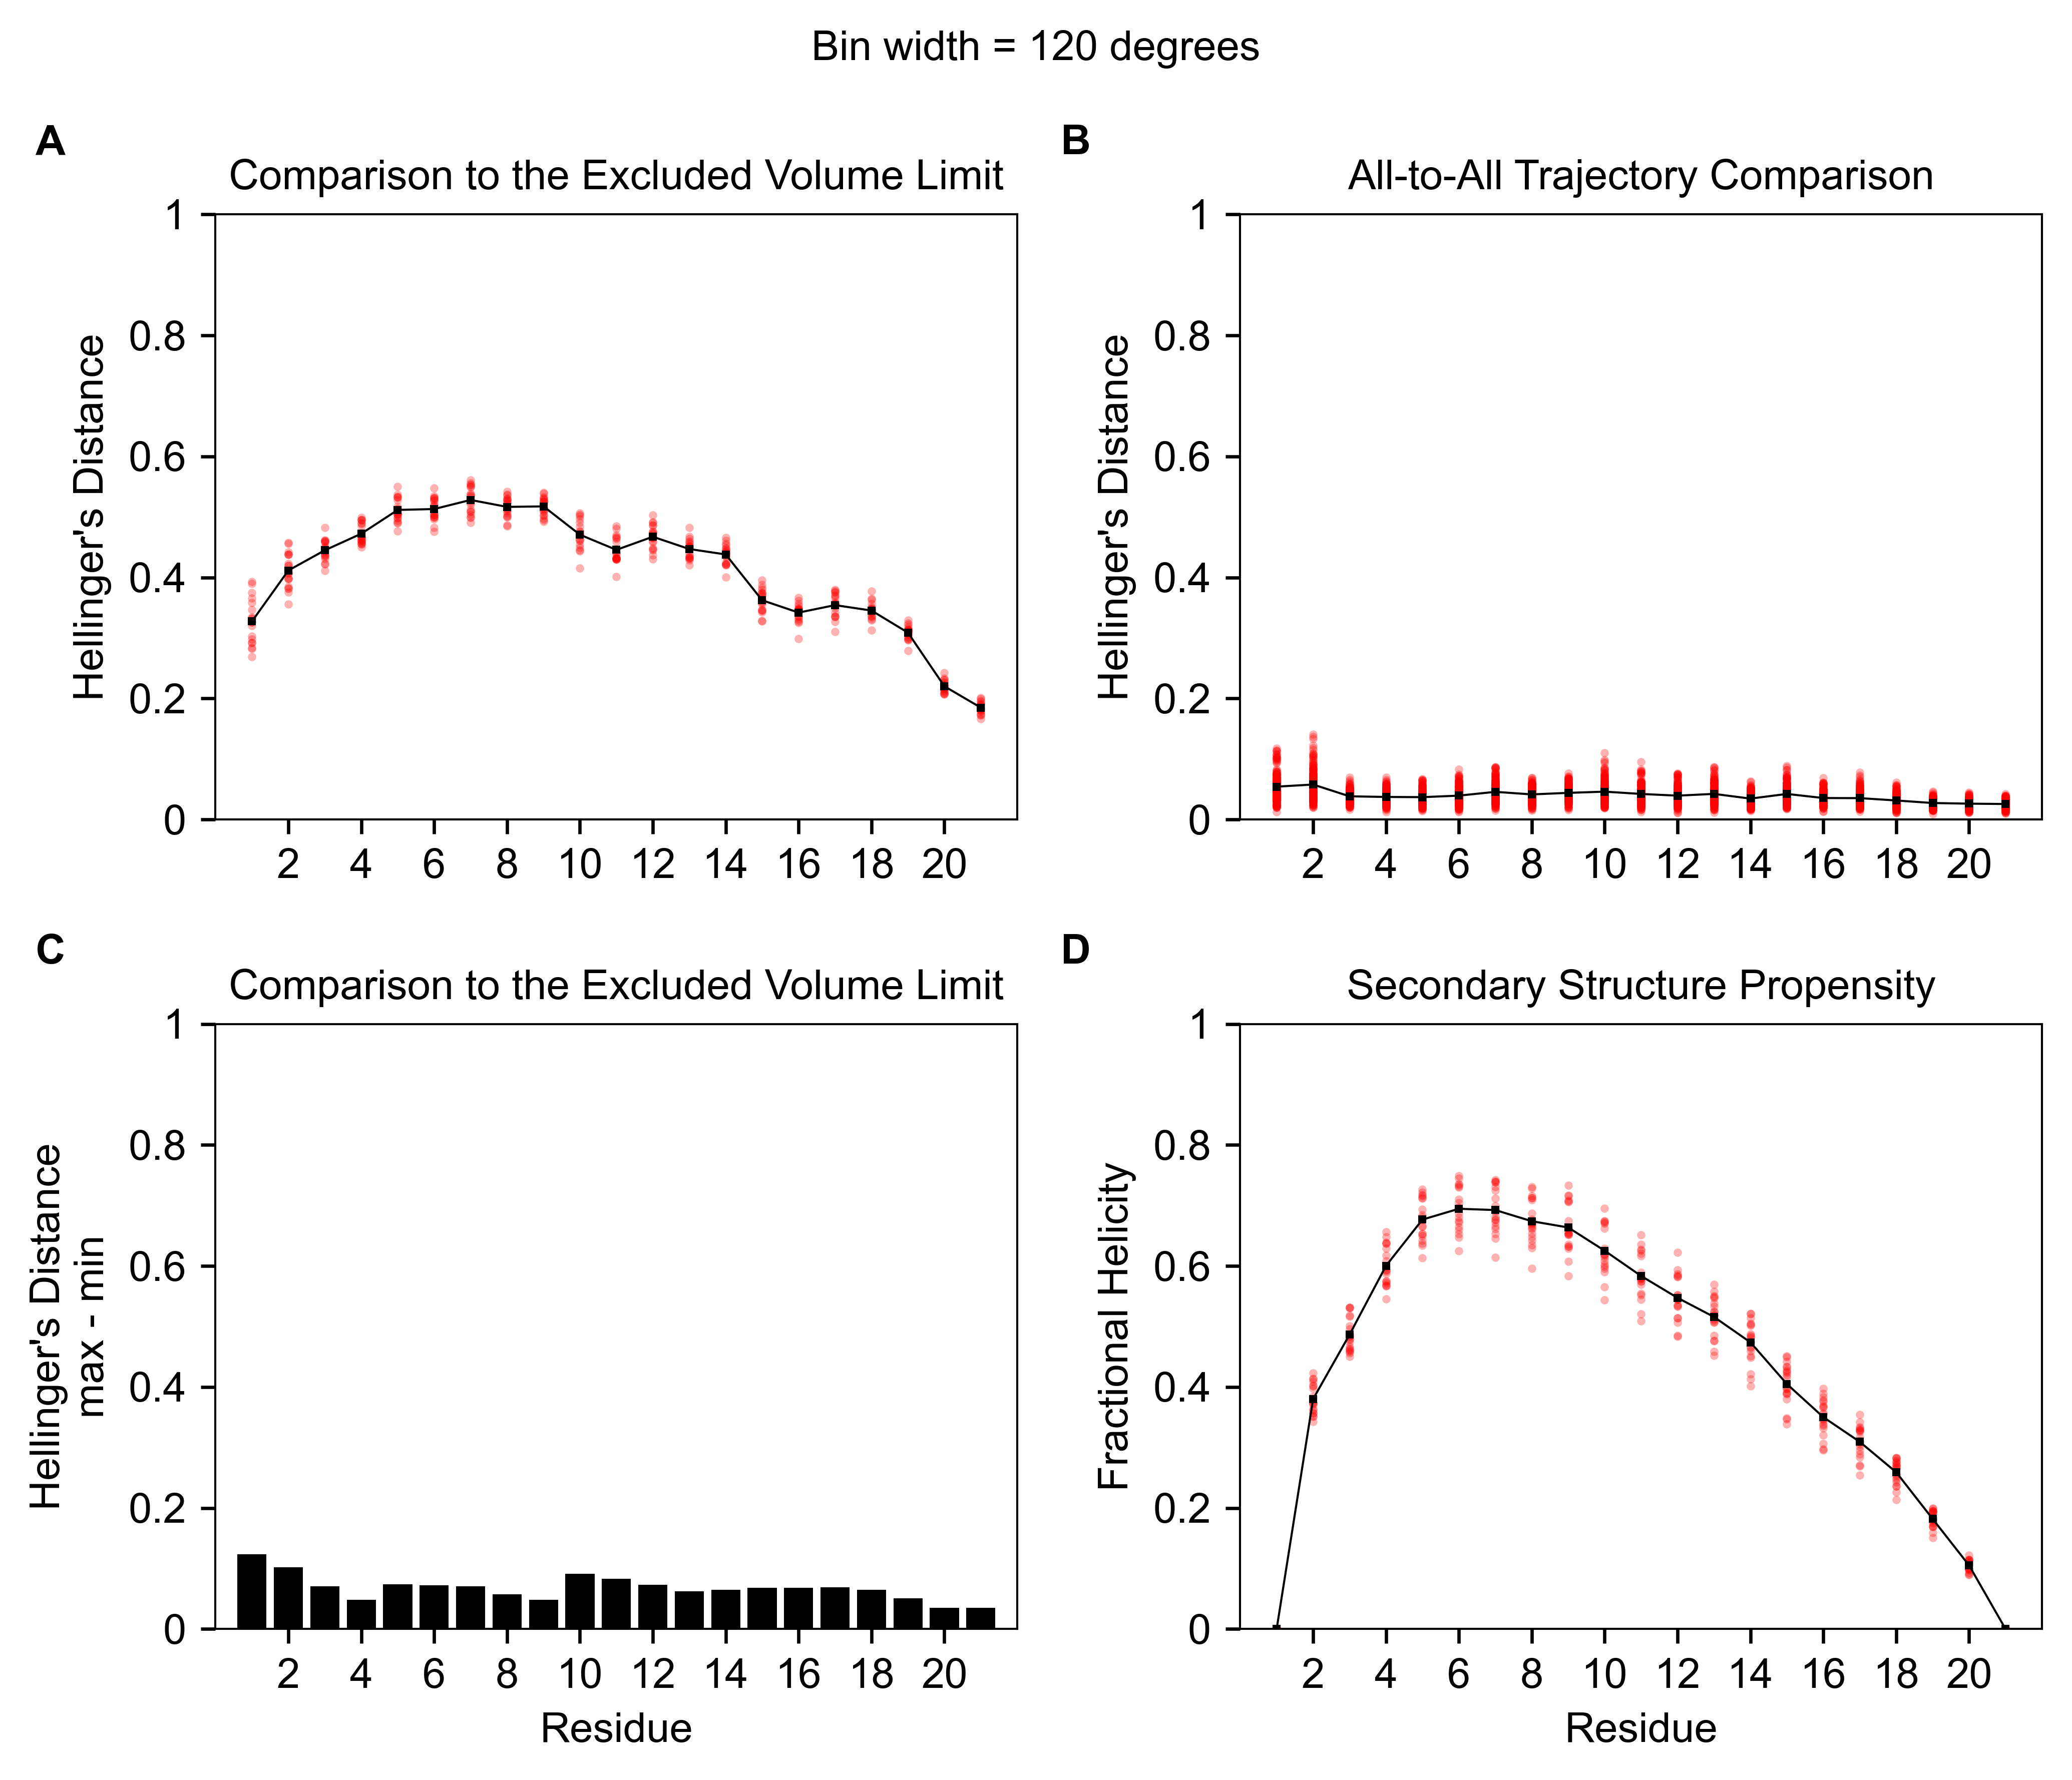

In [2]:
bin_widths = [5, 15, 30, 45, 60, 120]

ev_means, ata_means = [], []
for bw in bin_widths:
    qual = load_system("fs_peptide/full", "fs_peptide/ev", num_replicates=10, method="2D angle distributions",
                       bwidth_degrees=bw, verbose=False)
    fig, axd = penguin_figure(qual, dihedral="2D", increment=2, figsize=(7, 6), fontsize=10,
                              panel_labels=("A", "B", "C", "D"),
                              title=f"Bin width = {bw} degrees",
                              save_path=figure_path("si_figures", "fs_bin_width", f"fs_qual_2D_{bw}.pdf"))
    ev_means.append(np.mean(np.asarray(qual.hellingers_distances()), axis=0))
    ata_means.append(np.mean(np.asarray(qual.get_all_to_all_2d_trj_comparison()), axis=0))
ev_means = np.array(ev_means); ata_means = np.array(ata_means)

## Replicate-mean curves across bin widths (Figures S11 and S12)

(<Figure size 700x500 with 1 Axes>,
 <Axes: title={'center': 'All-to-All Trajectory Mean Comparison Across Bin Widths'}, xlabel='Residue', ylabel="Hellinger's Distance">)

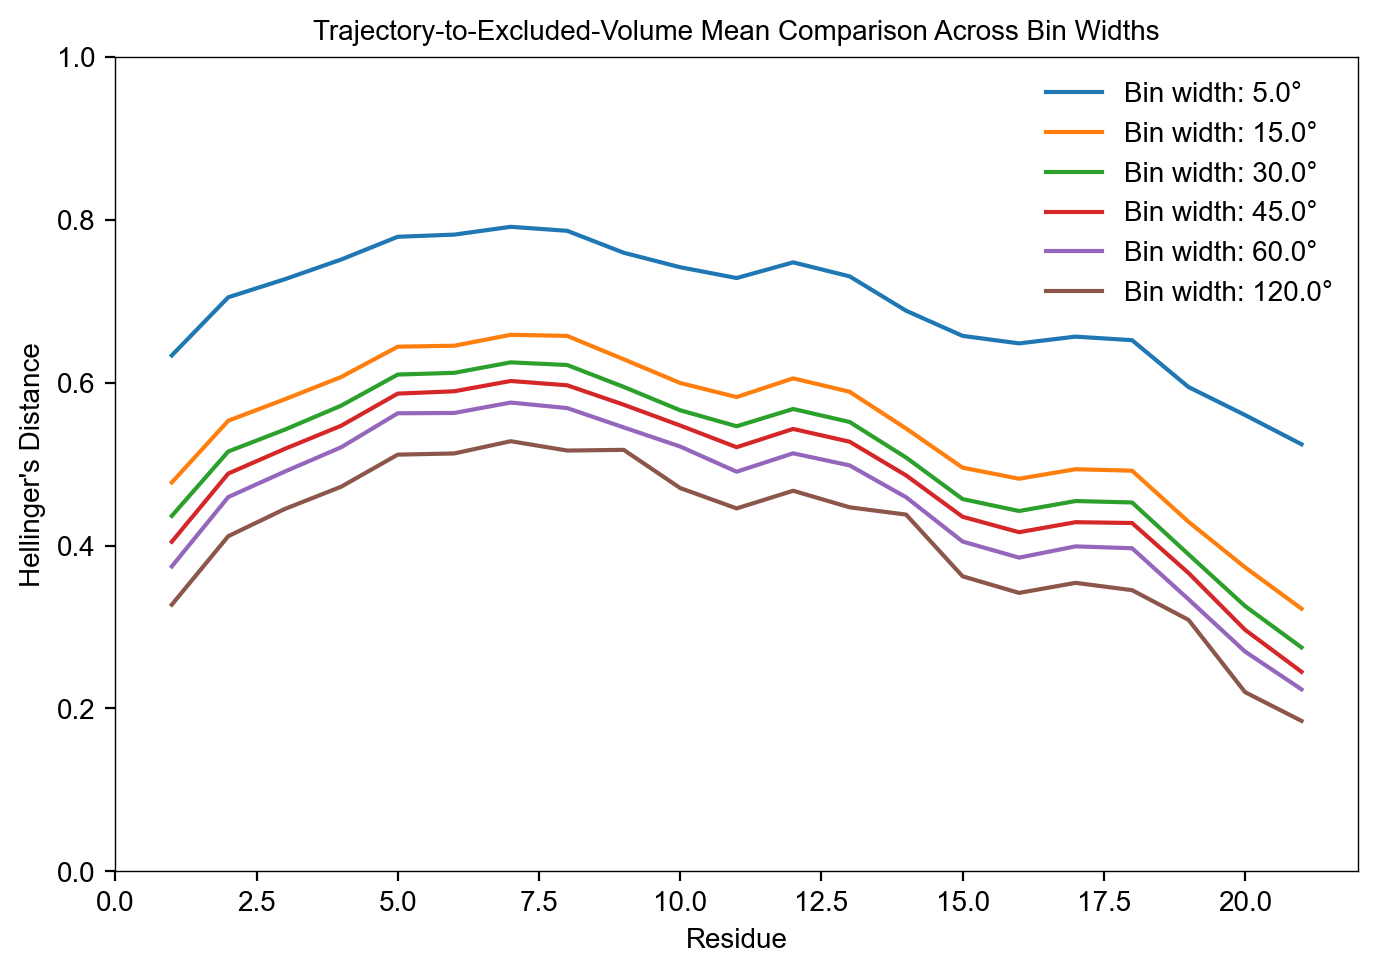

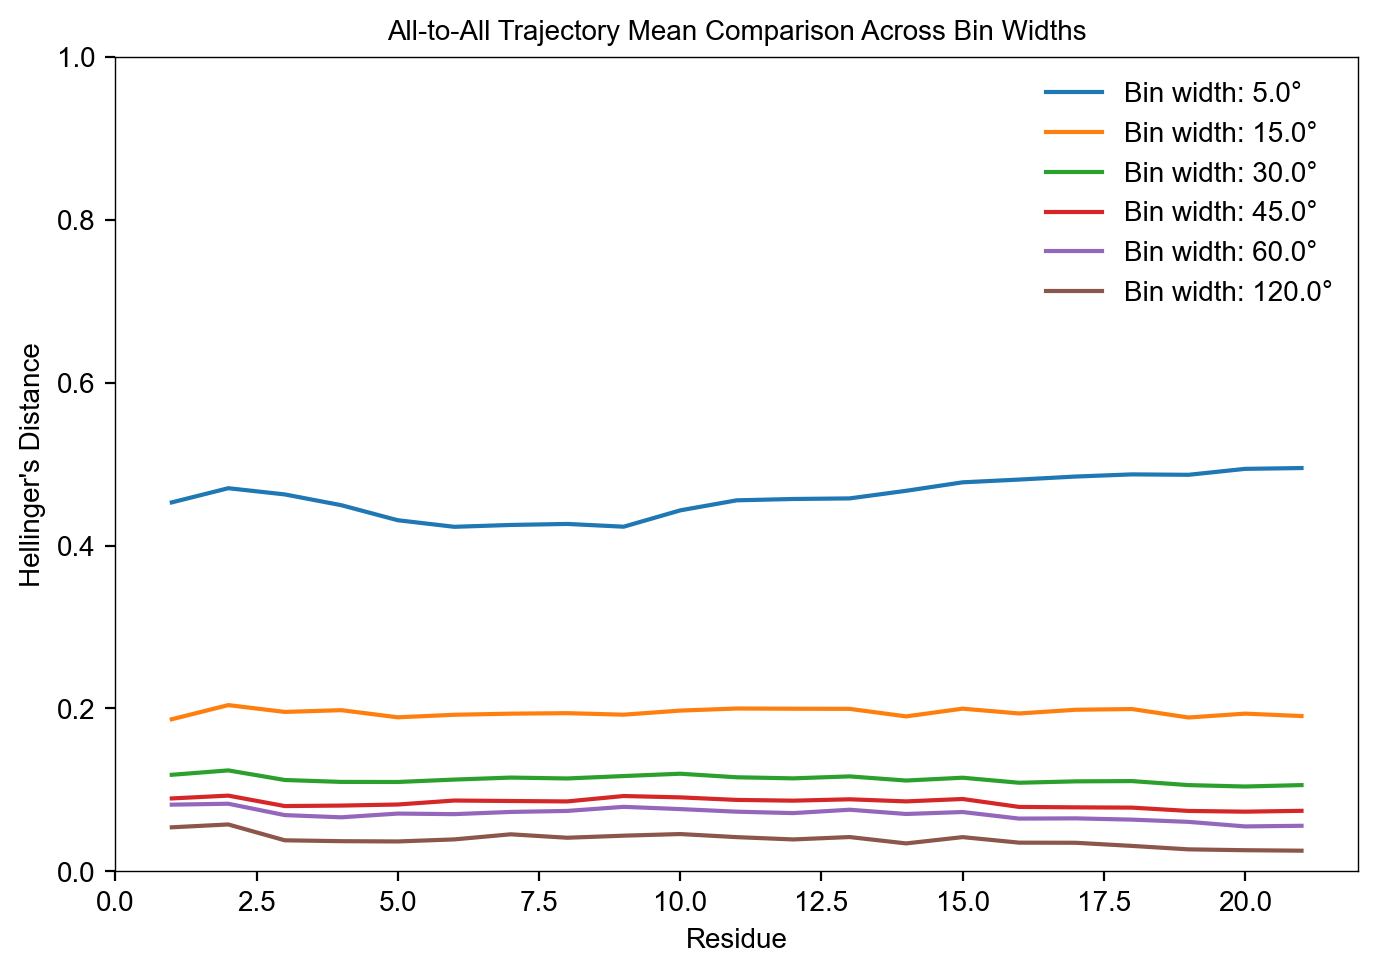

In [3]:
plot_bin_width_comparison(bin_widths, ev_means,
                          "Trajectory-to-Excluded-Volume Mean Comparison Across Bin Widths",
                          save_path=figure_path("si_figures", "fs_traj_to_excluded_volume_mean_bin_width_comparison.pdf"))
plot_bin_width_comparison(bin_widths, ata_means,
                          "All-to-All Trajectory Mean Comparison Across Bin Widths",
                          save_path=figure_path("si_figures", "fs_all_to_all_traj_mean_bin_width_comparison.pdf"))